In [3]:
# Install required external packages
!pip install pandas numpy matplotlib scikit-learn importlib

^C


In [3]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
import warnings

In [4]:
# 1. Get list of CSV files (modify folder name if needed)
data_folder = os.path.join(os.getcwd(), "../data")
csv_files = glob.glob(os.path.join(data_folder, "smart_meter_data_*.csv"))
print("Found files:", csv_files)

# 2. Load each CSV into a DataFrame
dataframes = [pd.read_csv(file) for file in csv_files]


Found files: ['c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_0.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_1.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_2.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_3.csv']


In [14]:
warnings.filterwarnings("ignore")

def preprocess_df(dataframes):
    """
    Preprocess a list of DataFrames:
      - Print missing values per column.
      - Convert the 'time' column to datetime with UTC conversion.
      - Remove timezone info, sort the DataFrame by 'time' and reset the index.
      - Drop the 'id' column if present.
      - Create new time-related features: hour, minute, second, day, and month.
    """
    processed = []
    for idx, df in enumerate(dataframes, start=1):
        print(f"\nDataFrame {idx}:")
        
        # Print missing value percentages and column names.
        missing_pct = df.isnull().mean() * 100
        print("Percentage of missing values per column:")
        print(missing_pct)
        print("Columns in DataFrame:")
        print(df.columns.tolist())
        
        # Convert 'time' column to datetime with UTC conversion.
        df['time'] = pd.to_datetime(df['time'], errors='coerce', utc=True)
        if df['time'].isnull().any():
            print("Warning: Some 'time' values could not be converted and are NaT!")
        # Remove timezone information (naive datetime)
        df['time'] = df['time'].dt.tz_convert(None)
        df.sort_values('time', inplace=True)
        df.reset_index(drop=True, inplace=True)
        
        # Drop the 'id' column if it exists.
        if 'id' in df.columns:
            df = df.drop(columns=['id'])
        
        # Create time-based features.
        df['hour'] = df['time'].dt.hour
        df['minute'] = df['time'].dt.minute
        df['second'] = df['time'].dt.second
        df['day'] = df['time'].dt.day
        df['month'] = df['time'].dt.month
        
        processed.append(df)
    return processed

def concat_dataframes_by_time(dataframes):
    """
    Concatenate a list of DataFrames into a single DataFrame and order the rows by 'time'.
    """
    combined_df = pd.concat(dataframes, ignore_index=True)
    combined_df['time'] = pd.to_datetime(combined_df['time'], errors='coerce')
    combined_df.sort_values('time', inplace=True)
    combined_df.reset_index(drop=True, inplace=True)
    return combined_df

def get_complete_time_series(df):
    """
    Group the concatenated DataFrame by device_id and serial_number,
    then return a list of groups (DataFrames) that have no missing values.
    """
    complete_series = []
    grouped = df.groupby(['device_id', 'serial_number'])
    
    ''' # List of device_id, serial_number combinations to skip
    exclude_ids = [
    ('2659da1f-9042-45c0-bf0a-625106aff7d1'),
    ('231e45ef-ca7a-4f80-be11-ac7e2da0274c'),
    ('a806abdf-9261-4d98-abd4-a519248214f0'),
    ('c72b9342-827b-484c-a16a-1b4019f47720'),
    ('fc529a25-d538-4c5b-b51e-2f27a3ce9f1a')
    ]
    '''
    for (device, serial), group in grouped:
        # Skip specified time series by device_id, serial_number combination
        #if (device) in exclude_ids:
        #    print(f"Skipping time series for device_id: {device}, serial_number: {serial} based on exclusion criteria.")
        #    continue
        
        # Ensure the group is sorted by time.
        group_sorted = group.sort_values('time')
        
        # Skip groups with any missing data.
        if group_sorted.isnull().any().any():
            print(f"Skipping time series for device_id: {device}, serial_number: {serial} due to missing data.")
            continue
        
        complete_series.append(group_sorted)
    return complete_series

def add_lag_features(df, columns, lag_freqs={'lag_1h':'1H', 
                                             'lag_12h':'12H', 
                                             'lag_24h':'24H', 
                                             'lag_1w':'7D'}):
    """
    Add lag features for the specified columns based on time differences.
    - First, adds a simple one-row lag.
    - Then, adds time-based lags using pd.merge_asof for given lag frequencies.
    """
    # Create a copy of the DataFrame to avoid modifying the original data.
    df = df.copy()
    
    # Ensure that the 'time' column is converted to datetime format.
    # If there are errors during conversion, they are coerced to NaT (Not a Time).
    df['time'] = pd.to_datetime(df['time'], errors='coerce')
    
    # Sort the DataFrame by the 'time' column in ascending order.
    df.sort_values('time', inplace=True)
    
    # ---------------------------
    # Simple one-row lag: Shift each specified column by 1 row.
    for col in columns:
        df[f'{col}_lag_1'] = df[col].shift(1)
    
    # ---------------------------
    # Time-based lags using pd.merge_asof:
    for suffix, lag_str in lag_freqs.items():
        lag_delta = pd.Timedelta(lag_str)
        df[f'time_shift_{suffix}'] = df['time'] - lag_delta
        temp = df[['time'] + columns].copy()
        rename_dict = {col: f'{col}_{suffix}' for col in columns}
        temp.rename(columns=rename_dict, inplace=True)
        merged = pd.merge_asof(
            df.sort_values(f'time_shift_{suffix}'),
            temp.sort_values('time'),
            left_on=f'time_shift_{suffix}',
            right_on='time',
            direction='backward',
            tolerance=pd.Timedelta(lag_str)
        )
        for col in columns:
            df[f'{col}_{suffix}'] = merged[f'{col}_{suffix}'].values
        
        df.drop(columns=[f'time_shift_{suffix}'], inplace=True)
    
    return df

# ---------------------------
# Main Processing Workflow
# ---------------------------

# 1. Preprocess each DataFrame.
processed_dfs = preprocess_df(dataframes)

# 2. Concatenate the processed DataFrames by time.
data_concat = concat_dataframes_by_time(processed_dfs)

# 3. Drop the column with 100% missing values (e.g., 'values_state').
data_concat.drop(columns='values_state', inplace=True, errors='ignore')

# 4. Group the data by device_id and serial_number, extracting only complete time series.
complete_time_series = get_complete_time_series(data_concat)
print(f"Number of complete time series: {len(complete_time_series)}")

# NEW: define exactly the lags & columns you want
lag_args = {
    'lag_5m':   '5T',
    'lag_1h':   '1H',
    'lag_24h':  '24H',
    'lag_168h': '168H'
}

columns_to_add_lag = [
    'total_power_active', 'total_power_reactive', 'total_power_apparent',
    'import_energy_active', 'export_energy_active',
    'import_energy_reactive', 'export_energy_reactive',
    'total_energy_active', 'total_energy_reactive'
]

# 5. For each complete time series, apply lag feature engineering.
processed_time_series = []
for ts in complete_time_series:
    ts_lagged = add_lag_features(
        ts,
        columns=columns_to_add_lag,
        lag_freqs=lag_args
    )
    processed_time_series.append(ts_lagged)

print(f"Processed {len(processed_time_series)} time series with lag features.")



DataFrame 1:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
total_power_reactive        0.0
total_power_apparent        0.0
import_energy_active        0.0
export_energy_active        0.0
import_energy_reactive      0.0
export_energy_reactive      0.0
total_energy_active         0.0
total_energy_reactive       0.0
hour                        0.0
minute                      0.0
second                      0.0
day                         0.0
month                       0.0
dtype: float64
Columns in DataFrame:
['time', 'device_id', 'serial_number', 'values_state', 'total_power_active', 'total_power_reactive', 'total_power_apparent', 'import_energy_active', 'export_energy_active', 'import_energy_reactive', 'export_energy_reactive', 'total_energy_active', 'total_energy_reactive', 'hour', 'minute', 'second', 'day', 'month']

DataFrame 2:
P

Processing time series for device 1


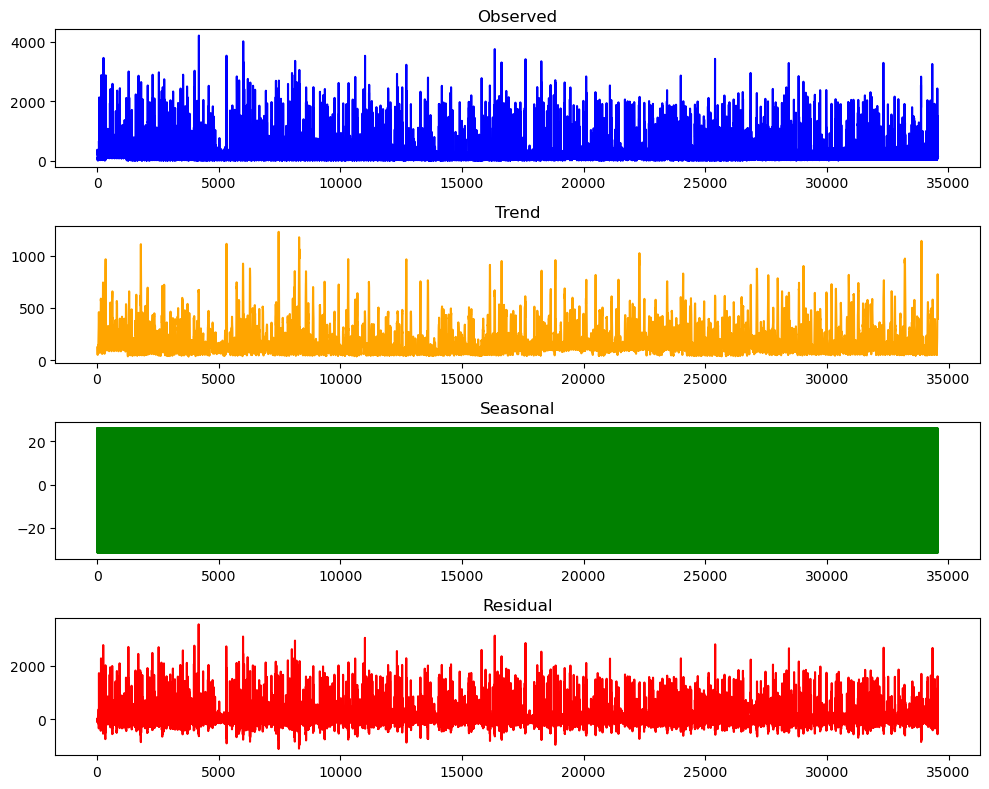

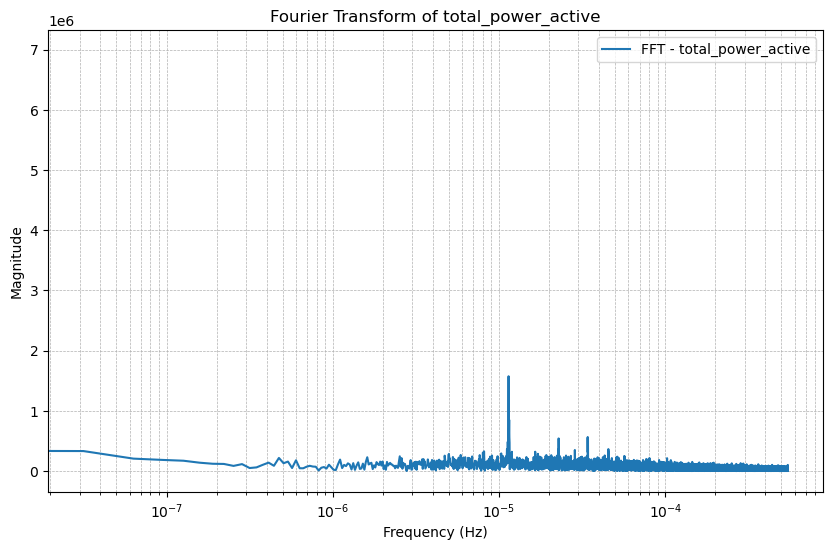

Processing time series for device 2


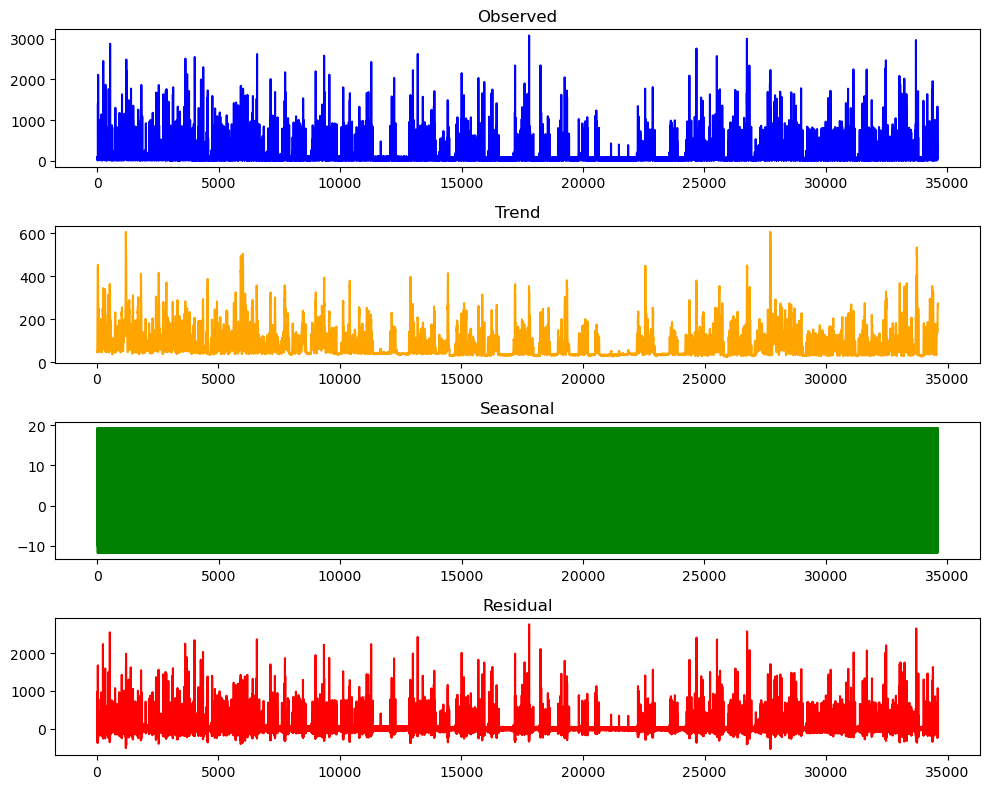

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from statsmodels.tsa.seasonal import seasonal_decompose

def plot_time_series_with_differencing_and_fft(df, variable='total_power_active', differencing=False, aggregation_period=None):
    """
    Plot the time series of a given variable and perform seasonal decomposition and FFT analysis.
    The plot is interactive for zooming and panning. Missing values are replaced by the mean and plotted in a different color.
    
    Parameters:
    - df: DataFrame with the time series data
    - variable: Column to plot (e.g., 'total_power_active')
    - differencing: If True, apply first differencing to the series
    - aggregation_period: Number of data points per aggregation group (optional)
    """
    # Ensure 'time' is in datetime format
    df['time'] = pd.to_datetime(df['time'], errors='coerce')

    # Handling NaNs by replacing them with the mean of the variable
    mean_value = df[variable].mean()
    df_cleaned = df.copy()
    
    # Identify missing values
    missing_values = df_cleaned[variable].isna()
    
    # Replace NaNs with mean values
    df_cleaned[variable] = df_cleaned[variable].fillna(mean_value)
    
    if differencing:
        # Apply differencing and drop NaN values that result from differencing
        df_cleaned[variable] = df_cleaned[variable].diff().dropna()

    # Drop any remaining NaNs after differencing (if they exist)
    df_cleaned = df_cleaned.dropna(subset=[variable])

    # Aggregation step (if aggregation_period is provided)
    if aggregation_period is not None:
        # Ensure the aggregation is based on the index (or by time if needed)
        df_cleaned = df_cleaned.iloc[:len(df_cleaned) // aggregation_period * aggregation_period]  # Ensure clean grouping
        df_cleaned = df_cleaned.groupby(np.arange(len(df_cleaned)) // aggregation_period).agg({variable: 'mean', 'time': 'first'})

    # Make sure no NaNs are left before decomposition
    if df_cleaned[variable].isna().sum() > 0:
        print(f"missing values: {df_cleaned[variable].isna().sum()}")
        raise ValueError("There are still missing values in the data after processing!")

    # Plotting time series with Plotly for interactivity
    trace_clean = go.Scatter(x=df_cleaned['time'], y=df_cleaned[variable], mode='lines', name=f'{variable}', line=dict(color='blue'))
    
    # Highlight missing values in red (original data with NaNs)
    trace_missing = go.Scatter(x=df[missing_values]['time'], 
                               y=[mean_value] * missing_values.sum(), 
                               mode='markers', 
                               name='Missing Values', 
                               marker=dict(color='red', size=10, symbol='x'))

    layout = go.Layout(
        title=f'{variable} Time Series',
        xaxis={'title': 'Time'},
        yaxis={'title': variable},
        showlegend=True
    )

    fig = go.Figure(data=[trace_clean, trace_missing], layout=layout)
    fig.update_layout(xaxis_rangeslider_visible=True)  # Adding zoom functionality
    fig.show()

    # Seasonal Decomposition using statsmodels
    decomposition = seasonal_decompose(df_cleaned[variable], model='additive', period=24)
    fig, ax = plt.subplots(4, 1, figsize=(10, 8))
    decomposition.observed.plot(ax=ax[0], title="Observed", color='blue')
    decomposition.trend.plot(ax=ax[1], title="Trend", color='orange')
    decomposition.seasonal.plot(ax=ax[2], title="Seasonal", color='green')
    decomposition.resid.plot(ax=ax[3], title="Residual", color='red')
    plt.tight_layout()
    plt.show()

    # Fourier Transform (FFT)
    signal = df_cleaned[variable]
    fs = 1 / (df_cleaned['time'].diff().dt.total_seconds().mean())  # Sampling frequency based on time diff
    n = len(signal)
    fft_result = np.fft.fft(signal)
    freq = np.fft.fftfreq(n, d=1/fs)
    
    fft_result_shifted = np.fft.fftshift(fft_result)
    freq_shifted = np.fft.fftshift(freq)
    
    plt.figure(figsize=(10, 6))
    plt.plot(freq_shifted[int(n/2):], np.abs(fft_result_shifted[int(n/2):]), label=f"FFT - {variable}")
    plt.xscale("log")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.title(f"Fourier Transform of {variable}")
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    plt.legend()
    plt.show()

# Loop through each time series for different devices
for idx, ts in enumerate(complete_time_series, start=1):
    print(f"Processing time series for device {idx}")
    plot_time_series_with_differencing_and_fft(ts, variable='total_power_active', differencing=False, aggregation_period=3)


In [12]:
def create_supervised_data_from_series(df, input_features, target_feature, window_size=1, step=1):
    """
    Converts a time series DataFrame into supervised learning data.
    For each time step t (starting at t=window_size), the input X is the flattened 
    window of the past `window_size` observations for the given input_features,
    and y is the target at time t.
    """
    X, y = [], []
    for i in range(window_size, len(df), step):
        window_data = df.iloc[i-window_size:i][input_features].values.flatten()
        X.append(window_data)
        y.append(df.iloc[i][target_feature])
    return np.array(X), np.array(y)

# Determine input features (exclude columns like time and identifiers).
all_columns = processed_time_series[0].columns.tolist()
input_features = [col for col in all_columns if col not in ['time', 'device_id', 'serial_number']]
target_feature = 'total_power_active'
window_size = 1
step = 1

# Prepare lists for training and testing datasets.
training_datasets = []
testing_datasets = []

for idx, ts in enumerate(processed_time_series):
    ts = ts.sort_values('time').reset_index(drop=True)

    # 1) build *all* supervised rows from this series
    X_all, y_all = create_supervised_data_from_series(
        ts, input_features, target_feature,
        window_size=window_size, step=step
    )

    # 2) drop any rows with NaNs (due to missing lags)
    mask = ~np.isnan(X_all).any(axis=1)
    X_all, y_all = X_all[mask], y_all[mask]

    # 3) now slice exactly 2000 for training, rest for testing
    train_count = 4032
    X_train = X_all[:train_count]
    y_train = y_all[:train_count]

    X_test  = X_all[train_count:]
    y_test  = y_all[train_count:]

    training_datasets.append({"X_train": X_train, "y_train": y_train})
    testing_datasets .append({"X_test":  X_test,  "y_test":  y_test })

    print(f"Series {idx}: got {X_train.shape[0]} train, {X_test.shape[0]} test")




Series 0: got 4032 train, 89693 test
Series 1: got 4032 train, 89592 test
Series 2: got 4032 train, 89618 test
Series 3: got 4032 train, 88917 test
Series 4: got 4032 train, 89686 test
Series 5: got 4032 train, 89748 test
Series 6: got 4032 train, 89326 test
Series 7: got 4032 train, 89875 test
Series 8: got 4032 train, 89932 test
Series 9: got 4032 train, 89647 test
Series 10: got 4032 train, 89916 test
Series 11: got 4032 train, 88920 test
Series 12: got 4032 train, 88916 test
Series 13: got 4032 train, 89846 test
Series 14: got 4032 train, 89610 test
Series 15: got 4032 train, 89658 test
Series 16: got 4032 train, 89484 test
Series 17: got 4032 train, 89764 test
Series 18: got 4032 train, 89822 test
Series 19: got 4032 train, 88911 test
Series 20: got 4032 train, 89553 test
Series 21: got 4032 train, 89816 test
Series 22: got 4032 train, 89853 test
Series 23: got 4032 train, 89574 test
Series 24: got 4032 train, 88957 test
Series 25: got 4032 train, 89246 test
Series 26: got 4032 tr

In [8]:
X_train.shape

(4032, 59)

In [2]:
import importlib
import src.ensemble_methods.elasticGBDT
import src.ensemble_methods.weightedElasticGBDT

importlib.reload(src.ensemble_methods.elasticGBDT)
from src.ensemble_methods.elasticGBDT import ElasticGBDT

importlib.reload(src.ensemble_methods.weightedElasticGBDT)
from src.ensemble_methods.weightedElasticGBDT import WeightedElasticGBDT

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import numpy as np

# Helper function to initialize elastic models for a given base model.
def initialize_models(base_model, y_train):
    # ElasticGBDT variants.
    model_index = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=38)
    model_contrib = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=1)
    model_ratio = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=1)
    elastic_models = {
        "Index-Based": model_index,
        "Contribution-Weighted-Based": model_contrib,
        "Ratio-Based": model_ratio,
    }
    # Weighted ElasticGBDT using the contribution-based relative update.
    weighted_model_contrib = WeightedElasticGBDT(
        pretrained_model=base_model,
        y_train=y_train,
        m_threshold=1,
        buffer_size=30,
        delta_bar_delta_init_lr=0.001
    )
    weighted_models = {
        "Weighted Contrib Rel": weighted_model_contrib
    }
    all_models = {}
    all_models.update(elastic_models)
    all_models.update(weighted_models)
    return all_models

# This list will hold per–time series statistics.
per_ts_results = []

# Process each of the 39 time series.
for ts_idx in range(5):
    print(f"\nProcessing Time Series {ts_idx}")
    
    # Retrieve training and testing datasets for this time series.
    X_train = training_datasets[ts_idx]["X_train"]
    y_train = training_datasets[ts_idx]["y_train"]
    X_test  = testing_datasets[ts_idx]["X_test"]
    y_test  = testing_datasets[ts_idx]["y_test"]
    
    # Filter out any rows with NaNs from the training set.
    mask_train = ~np.isnan(X_train).any(axis=1)
    X_train = X_train[mask_train]
    y_train = y_train[mask_train]
    
    # (Optionally, you can do a similar filtering for X_test if needed.)
    
    # Train a new base model on this time series' training set.
    base_model = GradientBoostingRegressor(
        n_estimators=40,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    )
    base_model.fit(X_train, y_train)
    
    # Initialize elastic models for this time series.
    models = initialize_models(base_model, y_train)
    
    # Set batch size for online forecasting.
    batch_size = 30
    n_batches = X_test.shape[0] // batch_size
    print(f"Time Series {ts_idx}: {X_test.shape[0]} test samples in {n_batches} batches.")
    
    # Data structures to record statistics for this time series.
    ts_stats = {
        "plain_errors": [],
        "models": {},  # Each model records errors and trees deleted.
        "n_batches": n_batches
    }
    for name in models.keys():
        ts_stats["models"][name] = {"errors": [], "trees_deleted": []}
    plain_errors = []
    
    # Process the test set in batches.
    for batch in range(n_batches):
        start = batch * batch_size
        end = start + batch_size
        X_batch = X_test[start:end]
        y_batch = y_test[start:end]
        
        # Plain baseline: base model prediction (no update).
        y_pred_plain = base_model.predict(X_batch)
        err_plain = mean_absolute_error(y_batch, y_pred_plain)
        plain_errors.append(err_plain)
        
        # For each elastic model, predict then update.
        for name, model in models.items():
            trees_before = model.get_number_of_trees()
            y_pred = model.predict(X_batch)
            err = mean_absolute_error(y_batch, y_pred)
            ts_stats["models"][name]["errors"].append(err)
            
            # Call the appropriate update method.
            if name == "Index-Based":
                model.update_index_based(X_batch, y_batch)
            elif name == "Contribution-Weighted-Based":
                model.update_contribution_weighted_ratio(
                    X_batch, y_batch,
                    gamma_multiplier=0.1, beta_multiplier=0.2, alpha_multiplier=0.3, fixed_multiplier=0.6
                )
            elif name == "Ratio-Based":
                model.update_contribution_ratio_adapt(X_batch, y_batch, fixed_multiplier=0.4)
            elif name == "Weighted Contrib Rel":
                model.update_weights_by_contribution_rel(
                    X_new=X_batch,
                    y_new=y_batch,
                    bottom_quantile=0.1,
                    weight_threshold_ratio=0.1,
                    eps=1e-8,
                    k=0.5
                )
            
            trees_after = model.get_number_of_trees()
            td = max(0, trees_before - trees_after)
            ts_stats["models"][name]["trees_deleted"].append(td)
            
            # If trees were removed, rebuild them using buffered data.
            if td > 0:
                residuals = y_batch - model.predict(X_batch)
                model.build_incremental_trees(X_batch, residuals, number_of_incremental_trees=td)
    
    ts_stats["plain_errors"] = plain_errors
    ts_stats["avg_plain_mae"] = np.mean(plain_errors)
    for name, stats in ts_stats["models"].items():
        stats["avg_mae"] = np.mean(stats["errors"])
        stats["total_trees_deleted"] = np.sum(stats["trees_deleted"])
    per_ts_results.append(ts_stats)
    
    # Plot per–time series results.
    batches = np.arange(1, n_batches+1)
    plt.figure(figsize=(10, 6))
    plt.plot(batches, plain_errors, marker='o', linestyle='-', label="Plain Model")
    for name, stats in ts_stats["models"].items():
        plt.plot(batches, stats["errors"], marker='o', linestyle='-', label=name)
    plt.xlabel("Batch Number")
    plt.ylabel("MAE")
    plt.title(f"Time Series {ts_idx} - Batch-wise MAE")
    plt.legend()
    plt.grid(True)
    plt.show()
    
    plt.figure(figsize=(10, 6))
    for name, stats in ts_stats["models"].items():
        plt.plot(batches, stats["trees_deleted"], marker='o', linestyle='-', label=name)
    plt.xlabel("Batch Number")
    plt.ylabel("Trees Deleted")
    plt.title(f"Time Series {ts_idx} - Trees Deleted per Batch")
    plt.legend()
    plt.grid(True)
    plt.show()

print("Completed processing all 39 time series.")


ModuleNotFoundError: No module named 'src'

Aggregate Statistics Across All 39 Time Series:
                         Model  Overall Average MAE  Overall Trees Deleted
0                  Plain Model           370.274850                      0
1                  Index-Based           148.535801                   1908
2  Contribution-Weighted-Based           126.534696                  21784
3                  Ratio-Based           135.720804                  21999
4         Weighted Contrib Rel           104.422291                   4005


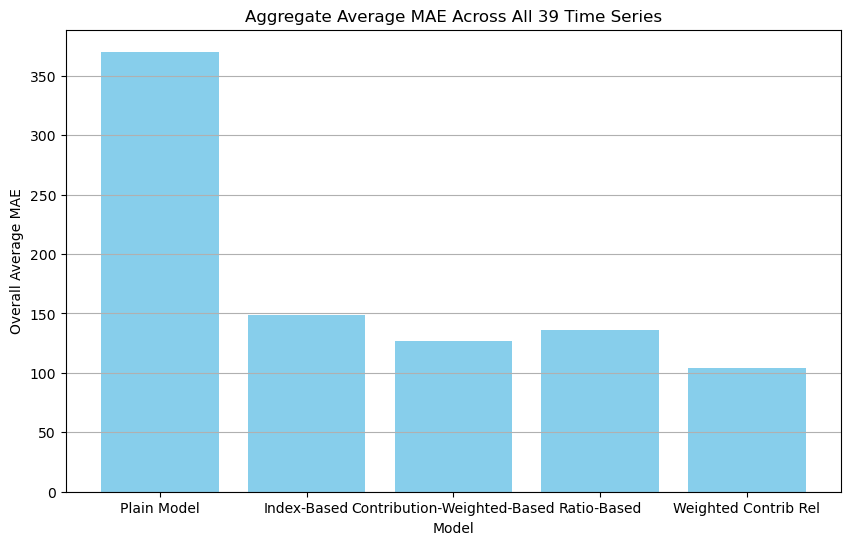

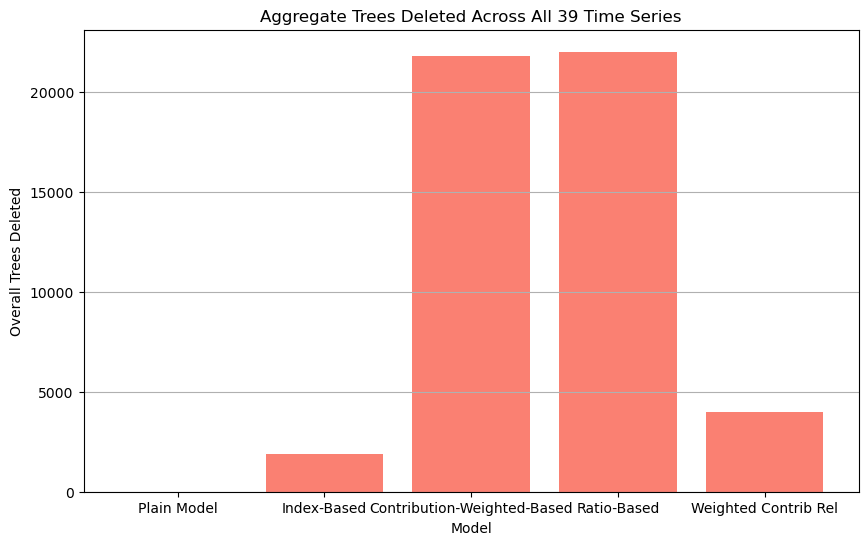

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Aggregate statistics for each model across all 39 time series.
model_names = list(per_ts_results[0]["models"].keys())
agg_results = {name: {"mae": [], "trees_deleted": []} for name in model_names}
plain_mae_all = []

for ts_stats in per_ts_results:
    plain_mae_all.append(ts_stats["avg_plain_mae"])
    for name in model_names:
        agg_results[name]["mae"].append(ts_stats["models"][name]["avg_mae"])
        agg_results[name]["trees_deleted"].append(ts_stats["models"][name]["total_trees_deleted"])

# Compute overall aggregates.
overall_results = []
for name in model_names:
    overall_avg_mae = np.mean(agg_results[name]["mae"])
    overall_trees_deleted = np.sum(agg_results[name]["trees_deleted"])
    overall_results.append({
        "Model": name,
        "Overall Average MAE": overall_avg_mae,
        "Overall Trees Deleted": overall_trees_deleted
    })
plain_overall_avg_mae = np.mean(plain_mae_all)
overall_results.insert(0, {
    "Model": "Plain Model",
    "Overall Average MAE": plain_overall_avg_mae,
    "Overall Trees Deleted": 0
})

overall_results_df = pd.DataFrame(overall_results)
print("Aggregate Statistics Across All 39 Time Series:")
print(overall_results_df)

# Plot overall average MAE per model.
plt.figure(figsize=(10, 6))
models_list = overall_results_df["Model"].tolist()
avg_mae_list = overall_results_df["Overall Average MAE"].tolist()
plt.bar(models_list, avg_mae_list, color='skyblue')
plt.xlabel("Model")
plt.ylabel("Overall Average MAE")
plt.title("Aggregate Average MAE Across All 39 Time Series")
plt.grid(axis='y')
plt.show()

# Plot overall trees deleted per model.
plt.figure(figsize=(10, 6))
trees_deleted_list = overall_results_df["Overall Trees Deleted"].tolist()
plt.bar(models_list, trees_deleted_list, color='salmon')
plt.xlabel("Model")
plt.ylabel("Overall Trees Deleted")
plt.title("Aggregate Trees Deleted Across All 39 Time Series")
plt.grid(axis='y')
plt.show()


Selected Time Series: 26
Training triggered.
Trained with 40 trees.
Weighted model trained.
Testing on 51614 samples in 1720 batches (batch size = 30).
Batch 1/1720: Plain MAE = 1665.9968, Weighted MAE = 0.0000, Trees removed = 0
Removing trees at indices [35] due to low relative weight.
Batch 2/1720: Plain MAE = 1674.9093, Weighted MAE = 0.0000, Trees removed = 1
Removing trees at indices [36] due to low relative weight.
Batch 3/1720: Plain MAE = 1692.7344, Weighted MAE = 0.0000, Trees removed = 1
Batch 4/1720: Plain MAE = 1692.7344, Weighted MAE = 0.0000, Trees removed = 0
Removing trees at indices [31] due to low relative weight.
Batch 5/1720: Plain MAE = 1662.0763, Weighted MAE = 0.0000, Trees removed = 1
Batch 6/1720: Plain MAE = 1462.7987, Weighted MAE = 0.0000, Trees removed = 0
Batch 7/1720: Plain MAE = 1489.8918, Weighted MAE = 0.0000, Trees removed = 0
Batch 8/1720: Plain MAE = 1665.9968, Weighted MAE = 0.0000, Trees removed = 0
Batch 9/1720: Plain MAE = 1665.9968, Weighted M

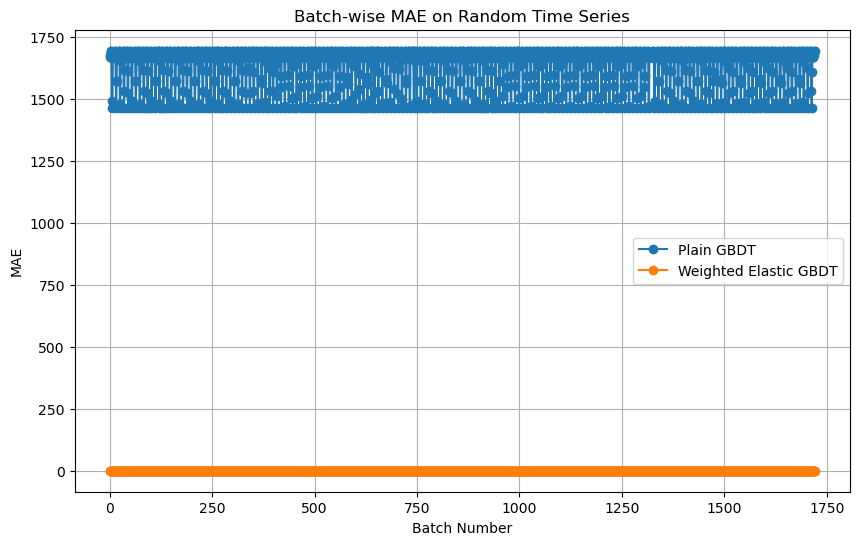

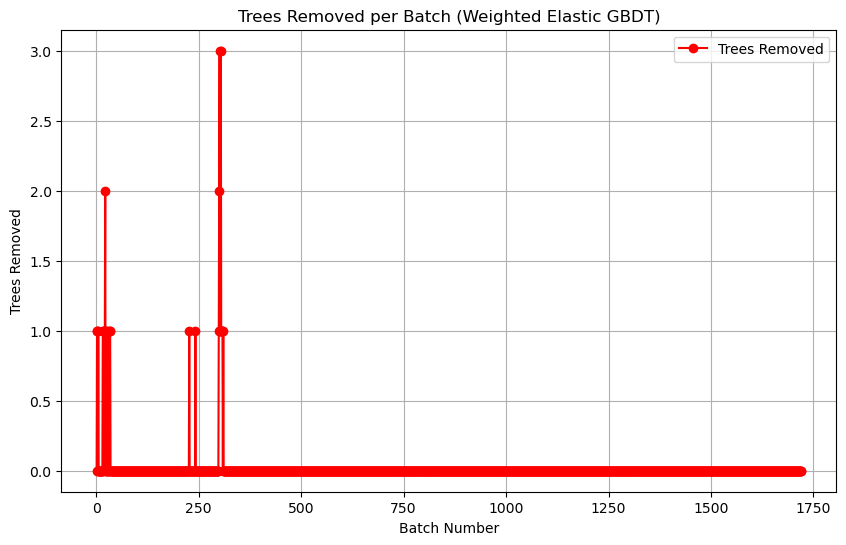

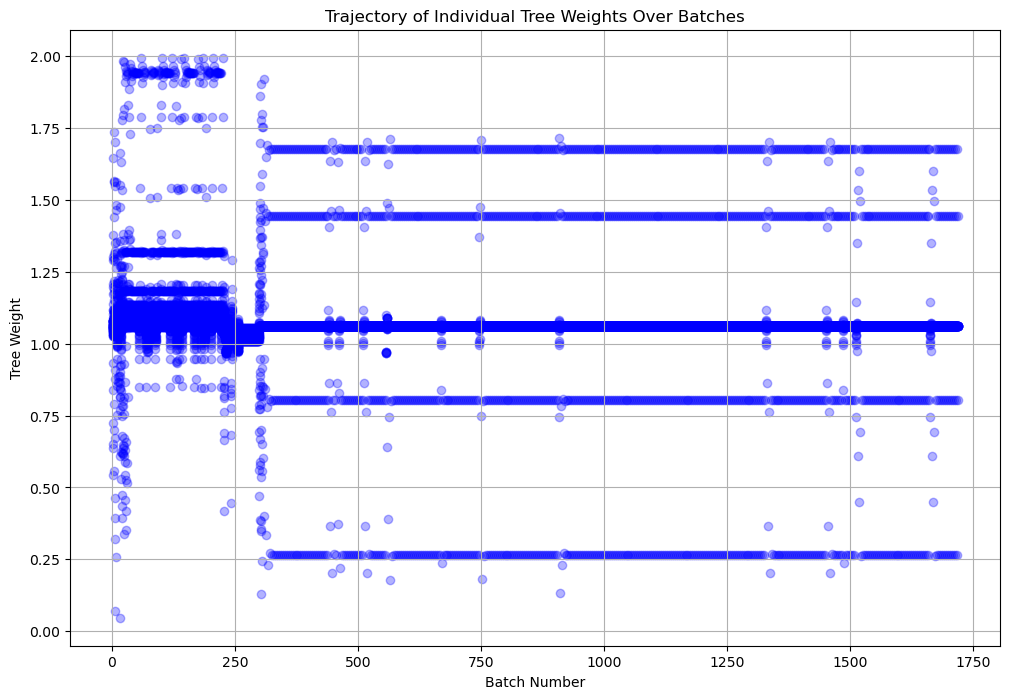

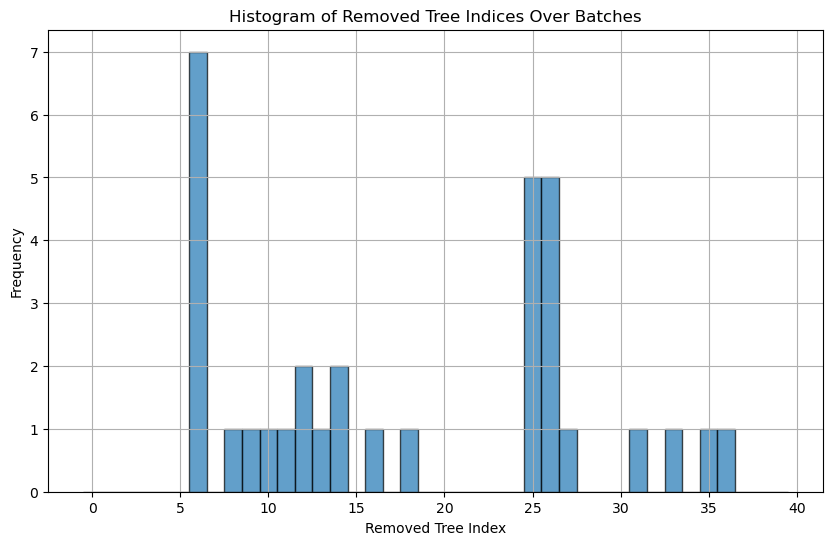

In [168]:
import importlib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# Reload your model modules if needed.
import src.elasticGBDT
importlib.reload(src.elasticGBDT)
from src.elasticGBDT import ElasticGBDT

import src.weightedElasticGBDT
importlib.reload(src.weightedElasticGBDT)
from src.weightedElasticGBDT import AccuracyUpdatedGBDT  # our modified class

# --- Select one random time series from the 39 ---
random_ts_idx = 26
print(f"Selected Time Series: {random_ts_idx}")

# Retrieve training and testing data for this time series.
data_train = training_datasets[random_ts_idx]
data_test  = testing_datasets[random_ts_idx]
X_train, y_train = data_train["X_train"], data_train["y_train"]
X_test, y_test   = data_test["X_test"], data_test["y_test"]

# Ensure no NaNs in training data.
mask = ~np.isnan(X_train).any(axis=1)
X_train = X_train[mask]
y_train = y_train[mask]

''' 
# Train a plain base model for comparison.
plain_model = GradientBoostingRegressor(
n_estimators=40,
learning_rate=0.1,
max_depth=5,
random_state=42
)
plain_model.fit(X_train, y_train)
print("Plain base model trained.")
'''


# Initialize the weighted model.
weighted_model = AccuracyUpdatedGBDT(
    y_train=y_train,
    alpha=0.1,         # using same learning rate as base model
    max_depth=5,
    random_state=42,
    buffer_size=600,    # fixed buffer size (e.g. 600 datapoints)
    num_trees=40,       # initial number of trees for training
    reg_coef= 1.5,
    error_damping= 0.8
)
# Train the weighted model's ensemble.
weighted_model.train(X_train, y_train)
print("Weighted model trained.")

# Prepare data structures for recording statistics.
plain_errors = []
weighted_errors = []
weighted_trees_deleted = []  # count of trees removed per batch
weights_history = []         # record weighted model's tree weights over time
removed_indices_history = [] # accumulate removed tree indices over batches

# Set a small batch size (e.g., 30 datapoints).
batch_size = 30
n_batches = X_test.shape[0] // batch_size
print(f"Testing on {X_test.shape[0]} samples in {n_batches} batches (batch size = {batch_size}).")

# Process the testing data in batches.
for batch in range(n_batches):
    start = batch * batch_size
    end = start + batch_size
    X_batch = X_test[start:end]
    y_batch = y_test[start:end]
    
    # Plain model prediction.
    y_pred_plain = plain_model.predict(X_batch)
    err_plain = mean_absolute_error(y_batch, y_pred_plain)
    plain_errors.append(err_plain)
    
    # Weighted elastic model prediction.
    y_pred_weighted = weighted_model.predict(X_batch)
    err_weighted = mean_absolute_error(y_batch, y_pred_weighted)
    weighted_errors.append(err_weighted)
    
    # Record current number of trees before update.
    trees_before = weighted_model.get_number_of_trees()
    
    # Update the weighted model and capture removed tree indices.
    removed_indices = weighted_model.update_weights_by_contribution_rel(
        X_new=X_batch,
        y_new=y_batch,
        weight_threshold_ratio=0.01,
        eps=1e-8)
    
    if removed_indices is not None:
        removed_indices_history.extend(removed_indices)
    
    trees_after = weighted_model.get_number_of_trees()
    trees_removed = max(0, trees_before - trees_after)
    weighted_trees_deleted.append(trees_removed)

    # Record the current weights trajectory.
    weights_history.append(np.copy(weighted_model.weights))
    
    print(f"Batch {batch+1}/{n_batches}: Plain MAE = {err_plain:.4f}, Weighted MAE = {err_weighted:.4f}, Trees removed = {trees_removed}")

# Plot the batch-wise MAE.
batches = np.arange(1, n_batches+1)
plt.figure(figsize=(10,6))
plt.plot(batches, plain_errors, marker='o', linestyle='-', label="Plain GBDT")
plt.plot(batches, weighted_errors, marker='o', linestyle='-', label="Weighted Elastic GBDT")
plt.xlabel("Batch Number")
plt.ylabel("MAE")
plt.title("Batch-wise MAE on Random Time Series")
plt.legend()
plt.grid(True)
plt.show()

# Plot trees removed per batch (for the weighted model).
plt.figure(figsize=(10,6))
plt.plot(batches, weighted_trees_deleted, marker='o', linestyle='-', color='red', label="Trees Removed")
plt.xlabel("Batch Number")
plt.ylabel("Trees Removed")
plt.title("Trees Removed per Batch (Weighted Elastic GBDT)")
plt.legend()
plt.grid(True)
plt.show()

# Plot the trajectory of the individual trees' weights.
plt.figure(figsize=(12, 8))
if all(len(w) == len(weights_history[0]) for w in weights_history):
    n_trees = len(weights_history[0])
    for j in range(n_trees):
        traj = [weights_history[i][j] for i in range(len(weights_history))]
        plt.plot(range(1, len(weights_history)+1), traj, alpha=0.3)
else:
    for i, w in enumerate(weights_history):
        plt.scatter([i+1]*len(w), w, color='blue', alpha=0.3)
plt.xlabel("Batch Number")
plt.ylabel("Tree Weight")
plt.title("Trajectory of Individual Tree Weights Over Batches")
plt.grid(True)
plt.show()

# Plot a histogram of the removed tree indices over all batches.
if len(removed_indices_history) > 0:
    plt.figure(figsize=(10,6))
    # Define bins for each possible index (assuming maximum initial trees is self.num_trees)
    bins = np.arange(0, weighted_model.num_trees+1) - 0.5
    plt.hist(removed_indices_history, bins=bins, edgecolor='black', alpha=0.7)
    plt.xlabel("Removed Tree Index")
    plt.ylabel("Frequency")
    plt.title("Histogram of Removed Tree Indices Over Batches")
    plt.grid(True)
    plt.show()
else:
    print("No trees were removed over all batches.")



In [169]:
weighted_mae = np.mean(weighted_errors)
plain_mae = np.mean(plain_errors)
print(f"average plain MAE: {plain_mae}, average weighted model MAE: {weighted_mae}")

average plain MAE: 1632.6900776757827, average weighted model MAE: 2.6179704979749726e-05
